### Importing libraries

In [116]:
import pandas as pd
import matplotlib.pyplot as plt
from itables import show
import plotly.express as px

### Importing data

In [ ]:
items_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/items_data_processed/high_conf_items_processed_day.csv", sep=";", low_memory=False)
currency_processed = pd.read_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed.csv", sep=";", low_memory=False)

# Currency Purchasing Power Index 
based on real life CPI: Consumer Price Index

In the early days of a league, many items are not yet traded or appear only later as players progress. This means that the item basket is incomplete on some days, especially at the beginning of the league. Because of this, normalising prices to the first day can produce misleading results. To avoid this problem, the index was calculated using a basket of currencies, which are available every day and actively traded from the start of the league.

### Currency basket

In [107]:
currency_basket = ["Divine Orb","Exalted Orb","Orb of Fusing","Orb of Alchemy","Chromatic Orb","Orb of Alteration","Sacred Orb","Glassblower's Bauble","Cartographer's Chisel","Stacked Deck" "Vaal Orb","Orb of Scouring","Gemcutter's Prism"]

In [110]:
# add the column "Day" indicates the day of the league

currency_processed["Date"] = pd.to_datetime(currency_processed["Date"])
currency_processed["Day"] = (
    currency_processed["Date"]
    - currency_processed.groupby("League")["Date"].transform("min")
).dt.days + 1

#exporting dataset
currency_processed.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_processed_day.csv",sep=";",index=False)

In [111]:
currency_processed.groupby("League")["Day"].max()

League
Affliction     110
Ancestor       110
Keepers        123
Mercenaries    137
Necropolis     117
Settlers       319
Name: Day, dtype: int64

In [112]:
# Select currency basket
currency_prices = currency_processed[currency_processed["Get"].isin(currency_basket)].copy()

Currencies in the basket have very different price levels.  **Divine Orb** cost usually hundreds of Chaos Orbs, while other currencies cost only a few Chaos or less than a Chaos. If we averaged the raw prices, expensive currencies would dominate the index and distort the result.

To avoid this, each currency is normalised to its price on the first day of the league. This transforms all currencies to a common relative scale, where the starting value equals 1. As a result, every currency contributes equally to the index, and the indicator reflects relative price changes over time rather than absolute price differences between currencies.

In [113]:
# Normalise each currency to its Day 1 price
currency_prices["Value_norm"] = (currency_prices["Value"] /currency_prices.groupby(["League", "Get"])["Value"].transform("first"))

In [114]:
# Currency CPI (mean of normalised prices per day)
curr_basket_price_per_day = (currency_prices.groupby(["League", "Day"])["Value_norm"].mean().reset_index(name="currency_index"))

#exporting dataset
curr_basket_price_per_day.reset_index(drop=True).to_csv("C:/Users/user/Desktop/Data Science/PoeMarketAnalyser/data/poeninja/currency_data_processed/currency_index.csv",sep=";",index=False)

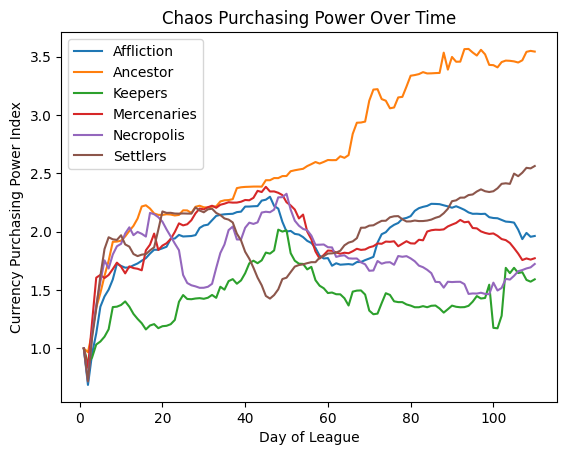

In [118]:
curr_basket_price_per_day110 = curr_basket_price_per_day[curr_basket_price_per_day["Day"] <= 110].copy()

for league, df_league in curr_basket_price_per_day110.groupby("League"):
    plt.plot(df_league["Day"],df_league["currency_index"],label=league)

plt.xlabel("Day of League")
plt.ylabel("Currency Purchasing Power Index")
plt.title("Chaos Purchasing Power Over Time")
plt.legend()

plt.show()


**Conclusions:**

The Chaos Purchasing Power Index allows comparison of the relative strength of the Chaos Orb across different leagues over time. Several patterns are visible:

**1. Early-league stabilisation**

Across all leagues, the purchasing power of Chaos Orbs increases rapidly during the first 10–20 days. This period likely reflects the early-stage market adjustment when the supply of currency and tradeable items begins to stabilise. After this phase, the market typically enters a more stable period.

**2. Differences in currency strength between leagues**

Clear differences in the strength of Chaos Orbs can be observed between leagues. The **Ancestor league** shows the highest purchasing power index, reaching values above 3.5, indicating that goods were relatively cheap in terms of Chaos Orbs. The purchasing power of the Chaos Orb in this league increases constantly throughout the league. In contrast, the **Keepers league** exhibits consistently lower values of the index, generally between 1.2 and 1.7, indicating weaker purchasing power of Chaos Orbs and relatively higher item prices.

**3. Moderate and stable economic behaviour**

Several leagues demonstrate relatively stable behaviour after the initial market adjustment. This suggests a relatively balanced relationship between currency supply and item availability.

**4. Mid-league inflation trend**

The analysis also reveals a common pattern across most leagues. With the exception of the **Ancestor league**, a clear decline in the Chaos Purchasing Power Index can be observed. This indicates that the purchasing power of the Chaos Orb decreases, meaning that goods become relatively more expensive in terms of Chaos Orbs. This trend begins approximately around the midpoint of the league and continues towards its later stages. Such a pattern suggests the emergence of mid-league inflation, likely driven by increasing upply of currency and a gradual saturation of player demand, as many players have already acquired the items they need.

**5. Increased volatility in specific leagues**

The **Necropolis league** displays noticeable short-term inflaction between 25-35 day of the league. Such volatility may reflect temporary shifts in player activity, farming strategies, or changes in demand for specific items.

**6. Overall economic patterns**

Despite differences in magnitude, all leagues share a broadly similar structural pattern:
    an initial adjustment period followed by a more gradual evolution of purchasing power. However, the level at which the index stabilises differs significantly between leagues, indicating that each league develops its own economic pattern.